In [1]:
import numpy as np
import scipy

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

import tifffile
import fastplotlib as fpl

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [3]:
%matplotlib inline

In [4]:
path = "/home/kushal/lab/datasets/jason/M19/D05/M19D5_MC.tif"
movie = tifffile.imread(path)[:10_000, 128:-138:2, 138:-132:2].astype(np.float32)

In [5]:
movie_mean = movie.mean(axis=0)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
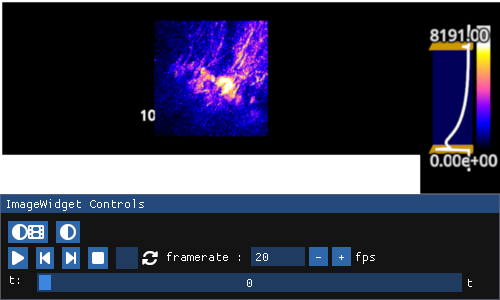

In [6]:
iw_movie = fpl.ImageWidget(movie, cmap="gnuplot2")
iw_movie.show()

In [7]:
iw_movie.window_funcs = {"t": (np.mean, 33)}

In [8]:
v1 = np.load("./v_ss-2.npy")

In [9]:
v1.min()

np.float64(-0.0006260856927162105)

In [10]:
v1.max()

np.float64(-2.1368003530401925e-07)

In [11]:
N_ROWS, N_COLS = 123, 121
n_pixels = N_ROWS * N_COLS
B = v1[0].reshape(n_pixels, n_pixels)
B = np.abs((B + B.T) / 2)

B.shape

(14883, 14883)

RFBOutputContext()

JupyterWgpuCanvas(css_height='900px', css_width='900px')
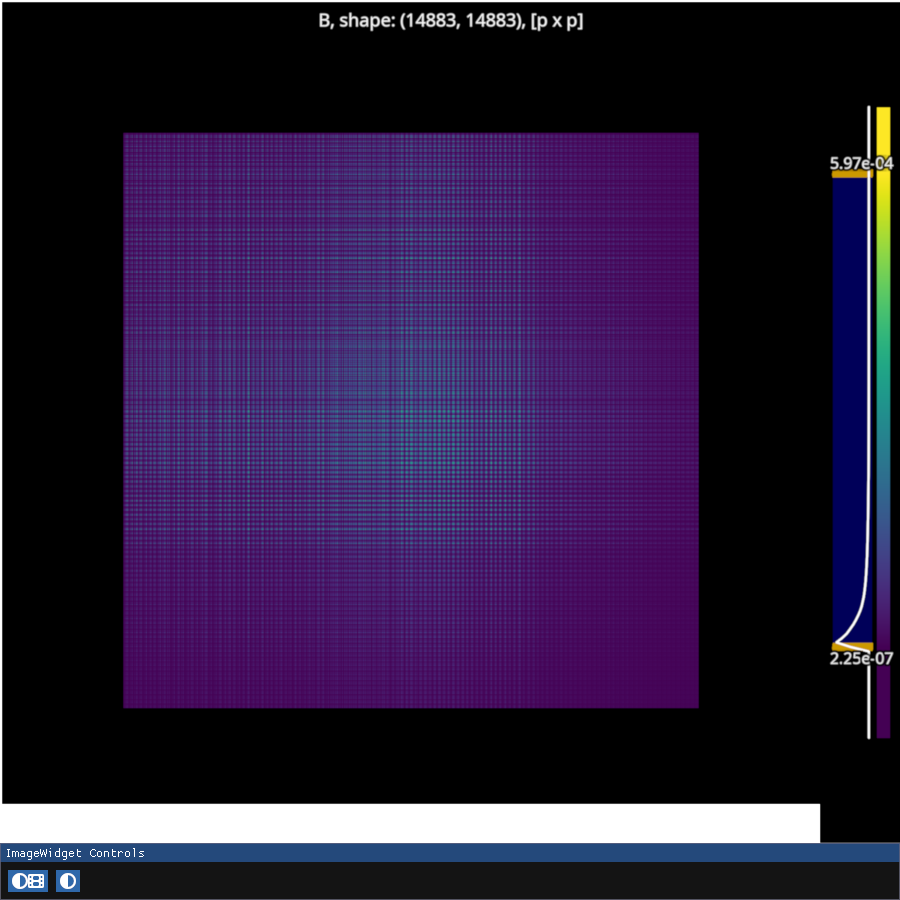

In [12]:
iw_adj = fpl.ImageWidget(
    B, 
    cmap="viridis",
    names=[f"B, shape: {B.shape}, [p x p]"],
    figure_kwargs={"size": (900, 900)},
)
iw_adj.show()

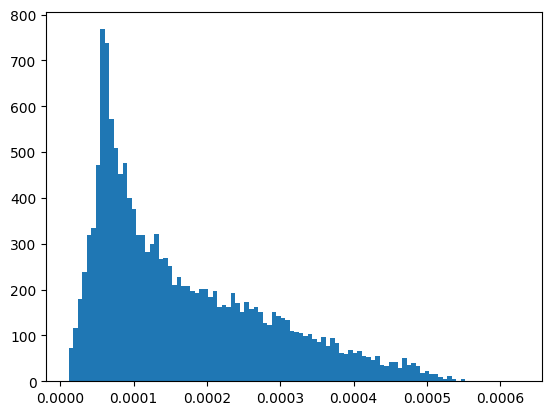

In [13]:
plt.hist(B.max(axis=1), bins=100)
plt.show()

# Determine columns/rowns which are just noise and exclude them

In [14]:
np.argsort(B.sum(axis=0))

array([14766, 14767, 14768, ...,  8792,  8192,  8794])

In [15]:
np.sum(B[14766, :])

np.float64(0.04641665180489722)

In [16]:
np.sum(B[8794, :])

np.float64(2.5013944978859315)

### background image, each pixel's value in the `bg_image` is the sum of that pixel's row/column from `B`

RFBOutputContext()

JupyterWgpuCanvas(css_height='700px', css_width='700px')
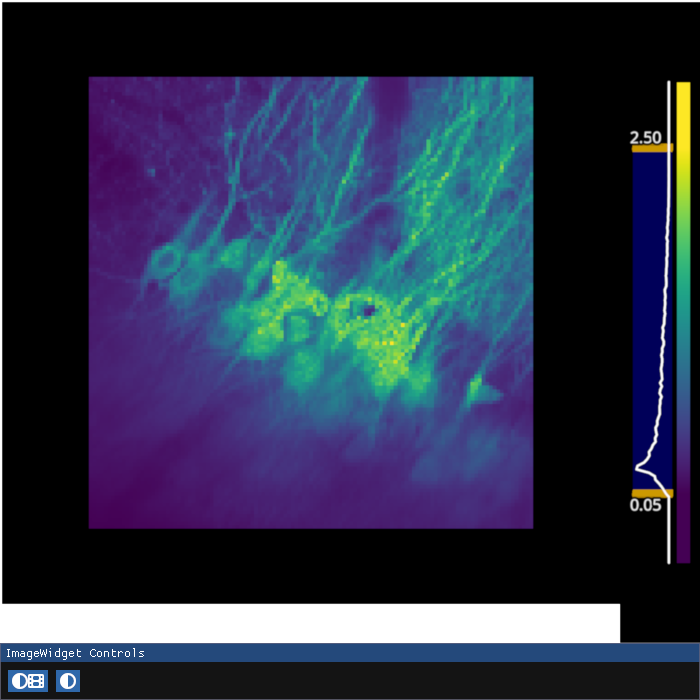

In [17]:
bg_image = B.sum(axis=0).reshape(N_ROWS, N_COLS)
iw_bg = fpl.ImageWidget(bg_image, cmap="viridis", figure_kwargs={"size": (700, 700)})
iw_bg.show()

## bg threshold

In [18]:
bg_threshold = 0.6
iw_bg.managed_graphics[0].vmin = 0.6

In [19]:
bg_ixs = B.sum(axis=0) < bg_threshold
bg_ixs

array([ True,  True,  True, ...,  True,  True,  True])

Used for mapping indices after bg removal back to original pixels in the image

In [20]:
NEW_IXS = np.where(B.sum(axis=0) > bg_threshold)[0]
NEW_IXS

array([   40,    51,    53, ..., 13051, 13052, 13171])

Number of bg pixels

In [21]:
np.count_nonzero(bg_ixs)

8215

# `B` without the bg rows and cols

In [22]:
B2 = B[~bg_ixs][:, ~bg_ixs]
B2.shape

(6668, 6668)

In [23]:
B2 = np.abs(B2 + B2.T) / 2

In [24]:
np.linalg.norm(B2 - B2.T, ord="fro")

np.float64(0.0)

## Eigendecomposition 

In [25]:
K_eig = 100

In [26]:
evals, Qk = scipy.sparse.linalg.eigsh(B2, k=100)

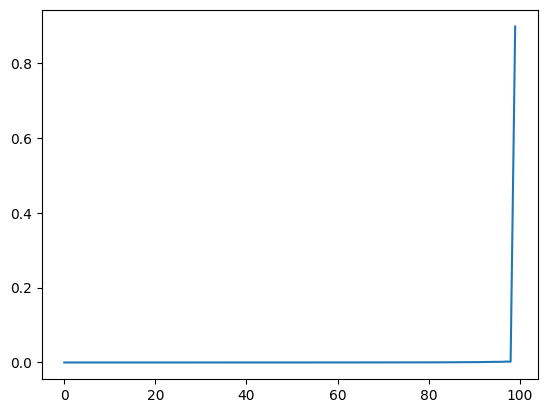

In [27]:
plt.plot(evals)

In [28]:
Qk.shape

(6668, 100)

In [29]:
Qk = Qk[:, ::-1]
evals = evals[::-1]

In [30]:
K_interp = 50

In [31]:
max_k, seed_ixs, proj = scipy.linalg.interpolative.interp_decomp(Qk.T[:K_interp], eps_or_k=0.001)
max_k

50

In [32]:
seed_ixs

array([5260,   77, 2932, ..., 6665, 6666, 6667], dtype=int32)

In [33]:
def coors_from_indices(indices: np.ndarray[int], k) -> np.ndarray:
    """get (x, y) image coordinates from the top `k` given flat pixel `indices`"""
    _ixs = NEW_IXS[indices[:k]]
    ys = np.floor_divide(_ixs, N_ROWS)
    xs = np.mod(_ixs, N_COLS)
    return np.column_stack([xs, ys])

In [34]:
seed_coors = coors_from_indices(seed_ixs, k=K_interp)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
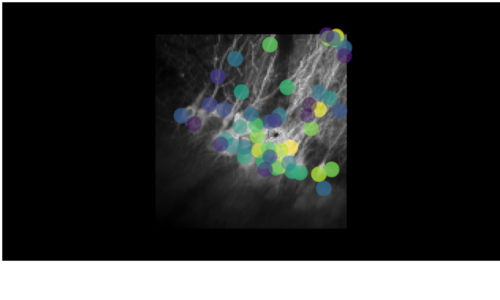

In [35]:
fig_seeds = fpl.Figure()

fig_seeds[0, 0].add_image(bg_image, cmap="gray")
fig_seeds[0, 0].add_scatter(seed_coors, sizes=15, cmap="viridis_r", alpha=0.7)

fig_seeds.show()

In [36]:
fig_seeds[0, 0].graphics[1].colors[:, -1] = 0.6

In [37]:
proj.shape

(50, 6618)

In [38]:
%matplotlib inline

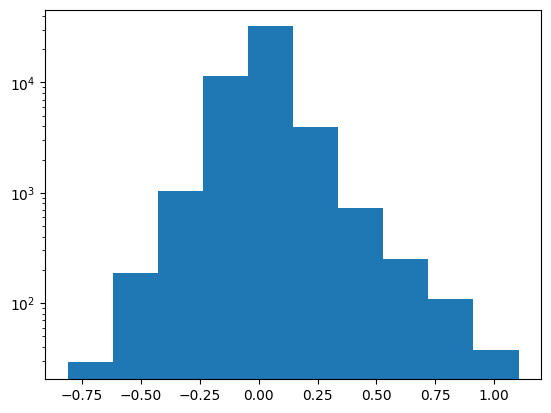

In [39]:
plt.hist(proj[:, :1000].ravel())
plt.semilogy()
plt.show()

# Threshold projection

In [40]:
proj_thres = proj.copy()
proj_thres[(proj_thres > -0.5) & (proj_thres < 0.5)] = 0

# reconstruct images from proj

In [41]:
def images_from_proj(projection, new_indices, projection_indices):
    """
    reconstruct images that represent each cluster from the interpolative decomposition projection

    Parameters
    ----------
    projection: np.ndarray
        projection
        
    k: int
        number of seeds that exist, this MUST hold: (k + projection.shape[1] = Qk.shape[0])

    new_indices: np.ndarray[int]
        indices that map from smaller-B matrix after thresholding to actual pixel indices in the original big B matrix

    projection_indices: np.ndarray[int]
        indices returned from interp decomp
    """
    k = projection.shape[0]
    
    images = np.zeros((k, N_ROWS * N_COLS))
    
    projection = np.hstack([np.eye(k), projection])

    indices = new_indices[projection_indices]

    for i in range(k):
        images[i, indices] = projection[i]

    return images.reshape((k, N_ROWS, N_COLS))

In [42]:
def images_from_proj2(projection, new_indices, projection_indices):
    k = projection.shape[0]
    
    images = np.zeros((k, N_ROWS * N_COLS))
    
    projection = np.hstack([np.eye(k) * 0, projection])

    indices = new_indices[projection_indices]

    for i in range(k):
        images[i, indices] = projection[i]

    return images.reshape((k, N_ROWS, N_COLS))

In [43]:
proj_images = images_from_proj(
    proj_thres, 
    new_indices=NEW_IXS, 
    projection_indices=seed_ixs
)

In [44]:
proj_images_raw = images_from_proj(
    proj, 
    new_indices=NEW_IXS, 
    projection_indices=seed_ixs
)

In [45]:
from ipywidgets import HBox, VBox

In [46]:
def coor_from_proj_ix(ix):
    a = np.zeros(seed_ixs.shape)
    img = np.zeros((N_ROWS * N_COLS))
    indices = NEW_IXS[seed_ixs]
    a[ix] = 1
    img[indices] = a
    return np.fliplr(np.argwhere(img.reshape(N_ROWS, N_COLS)))

In [47]:
seed_ixs.shape

(6668,)

In [48]:
proj.shape

(50, 6618)

In [49]:
coors_from_indices([seed_ixs[50]], k=1)

array([[70,  1]])

In [50]:
coor_from_proj_ix(50)

array([[70,  1]])

In [51]:
iw_proj = fpl.ImageWidget(
    proj, 
    cmap="seismic", 
    figure_kwargs={"size": (800, 750), "canvas": "glfw"},
)
iw_proj.figure[0, 0].set_title(f"selected row: 0")

ls_proj_row = iw_proj.managed_graphics[0].add_linear_selector(axis="y")
ls_proj_col = iw_proj.managed_graphics[0].add_linear_selector(axis="x")

iw_proj_comp = fpl.ImageWidget(
    [proj_images_raw[0], proj_images[0]],
    cmap="seismic",
    figure_shape=(2, 1),
    figure_kwargs={"size": (400, 750), "canvas": "glfw"},
)

iw_movie = fpl.ImageWidget(movie, cmap="gray", figure_kwargs={"size": (500, 575), "canvas": "glfw"})
iw_movie.figure[0, 0].add_scatter(np.fliplr(np.argwhere(proj_images[0])), colors="magenta", alpha=0.5, sizes=20, name="row-pixels")

a = np.zeros((50, seed_ixs.size - 50))
a[0, 0] = 1
col_point = np.fliplr(np.argwhere(images_from_proj2(a, new_indices=NEW_IXS, projection_indices=seed_ixs)[0]))

iw_movie.figure[0, 0].add_scatter(col_point, colors="cyan", alpha=0.5, sizes=7, name="col-pixel")


@ls_proj_row.add_event_handler("selection")
def update_proj_row(ev):
    ix = ev.get_selected_index()
    iw_proj_comp.set_data([proj_images_raw[ix], proj_images[ix]])
    
    iw_movie.figure[0, 0].delete_graphic(iw_movie.figure[0, 0]["row-pixels"])
    iw_movie.figure[0, 0].add_scatter(np.fliplr(np.argwhere(proj_images[ix])), colors="magenta", alpha=0.5, sizes=7, name="row-pixels")

    iw_proj.figure[0, 0].set_title(f"selected row: {ix}")

@ls_proj_col.add_event_handler("selection")
def update_proj_col(ev):
    ix = ev.get_selected_index()
    
    a = np.zeros((50, seed_ixs.size - 50))
    a[0, ix] = 1
    col_point = np.fliplr(np.argwhere(images_from_proj2(a, new_indices=NEW_IXS, projection_indices=seed_ixs)[0]))
    
    iw_movie.figure[0, 0].delete_graphic(iw_movie.figure[0, 0]["col-pixel"])
    iw_movie.figure[0, 0].add_scatter(col_point, colors="cyan", alpha=0.5, sizes=7, name="col-pixel")


# HBox([iw_proj.show(), iw_proj_comp.show(), iw_movie.show()])
iw_proj.show(), iw_proj_comp.show(), iw_movie.show()

(<wgpu.gui.glfw.GlfwWgpuCanvas at 0x7fac781a7690>,
 <wgpu.gui.glfw.GlfwWgpuCanvas at 0x7fac6811fe10>)

The surface texture is suboptimal.
Suboptimal present of frame 1
The surface texture is suboptimal.
Suboptimal present of frame 1
The surface texture is suboptimal.
Suboptimal present of frame 2
The surface texture is suboptimal.
Suboptimal present of frame 0
Draw error
Traceback (most recent call last):
  File "/home/kushal/repos/wgpu-py/wgpu/gui/_gui_utils.py", line 77, in log_exception
    yield
  File "/home/kushal/repos/wgpu-py/wgpu/gui/base.py", line 135, in _draw_frame_and_present
    self.draw_frame()
  File "/home/kushal/repos/fastplotlib/fastplotlib/layouts/_imgui_figure.py", line 109, in render
    super().render(draw)
  File "/home/kushal/repos/fastplotlib/fastplotlib/layouts/_figure.py", line 385, in render
    subplot.render()
  File "/home/kushal/repos/fastplotlib/fastplotlib/layouts/_subplot.py", line 142, in render
    super().render()
  File "/home/kushal/repos/fastplotlib/fastplotlib/layouts/_plot_area.py", line 345, in render
    child.render()
  File "/home/kushal/

In [49]:
Qk.shape

(6668, 100)

In [50]:
Qk2 = np.zeros((Qk.shape[0], 51))

In [55]:
Qk2[:, :50] = Qk[:, :50].copy()
Qk2[:, -1] = Qk[:, 39] - Qk[:, 12]

In [56]:
proj[12]

array([-0.01300157,  0.04657229, -0.02907071, ..., -0.10980928,
       -0.09900824, -0.15684291])

In [57]:
proj[39]

array([ 0.00450965, -0.03673574, -0.02623354, ...,  0.05349619,
        0.07988016,  0.08012232])

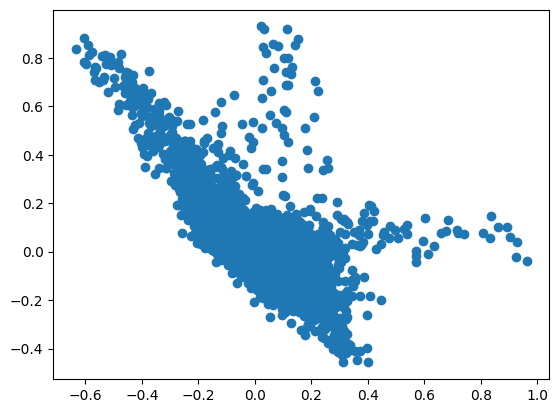

In [58]:
plt.scatter(proj[12], proj[39])

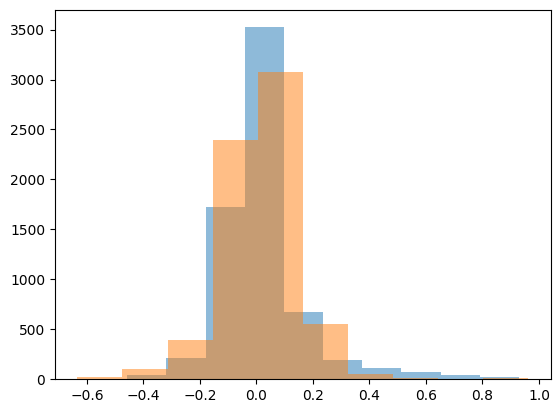

In [227]:
plt.hist(proj[39], alpha=0.5)
plt.hist(proj[12], alpha=0.5)
plt.show()

In [ ]:
dist = scipy.spatial.distance.squareform(scipy.spatial

In [242]:
np.linalg.norm(Qk[:, 39] - Qk[:, 12])

np.float64(1.4142135623730954)

In [244]:
np.linalg.norm(Qk[:, 0] - Qk[:, 1])

np.float64(1.4142135623730945)

In [245]:
Qk.shape

(6668, 100)

In [247]:
NEW_IXS[seed_ixs[39]], NEW_IXS[seed_ixs[12]]

(np.int64(5479), np.int64(798))

In [253]:
dist = np.zeros(Qk.shape[0])
for i in range(Qk.shape[0]):
    # print(Qk[:, i])
    dist[i] = np.linalg.norm(Qk[i] - (Qk[5479] - Qk[798]), ord=2)

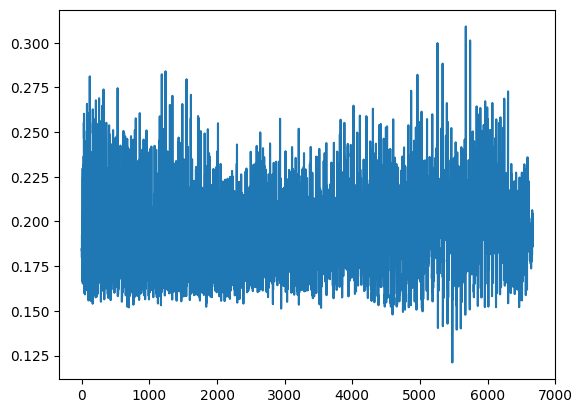

In [254]:
plt.plot(dist)

In [255]:
np.argmin(dist)

np.int64(5479)

In [250]:
iw_corr = fpl.ImageWidget(dist, cmap="seismic")
iw_corr.show()

ValueError: Your array has shape (50,) but you specified that each image in your array is 2D 

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
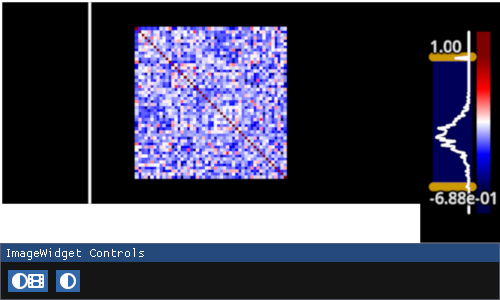

In [177]:
iw_corr = fpl.ImageWidget(np.corrcoef(proj), cmap="seismic")
iw_corr.show()

<Axes: >

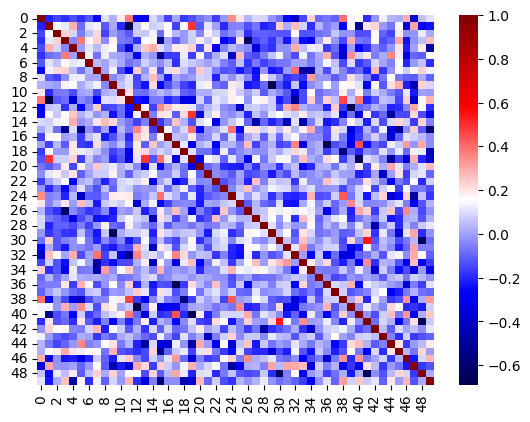

In [178]:
sns.heatmap(np.corrcoef(proj), cmap="seismic")

In [185]:
np.corrcoef(proj)[12, 39]

np.float64(-0.6880941316750309)

In [183]:
np.argmin(np.corrcoef(proj))

np.int64(639)

In [184]:
np.floor(639 / 50), np.mod(639, 50)

(np.float64(12.0), np.int64(39))

# Add selector to choose column and show which pixel that is, and then show value of that pixel in other rows

In [106]:
iw_movie.window_funcs = {"t": (np.mean, 23)}

In [58]:
ls_proj.get_selected_index()

37

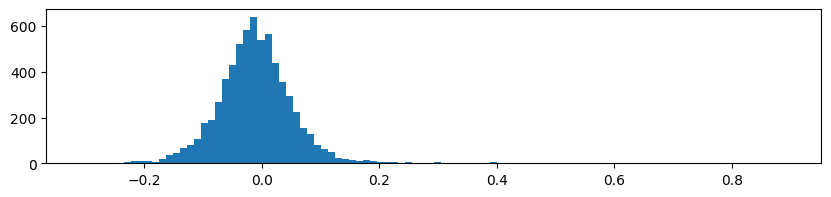

In [54]:
f = plt.figure(figsize=(10, 2))
plt.hist(proj[0], bins=100)
plt.show()

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas(css_height='1500px', css_width='1800px')
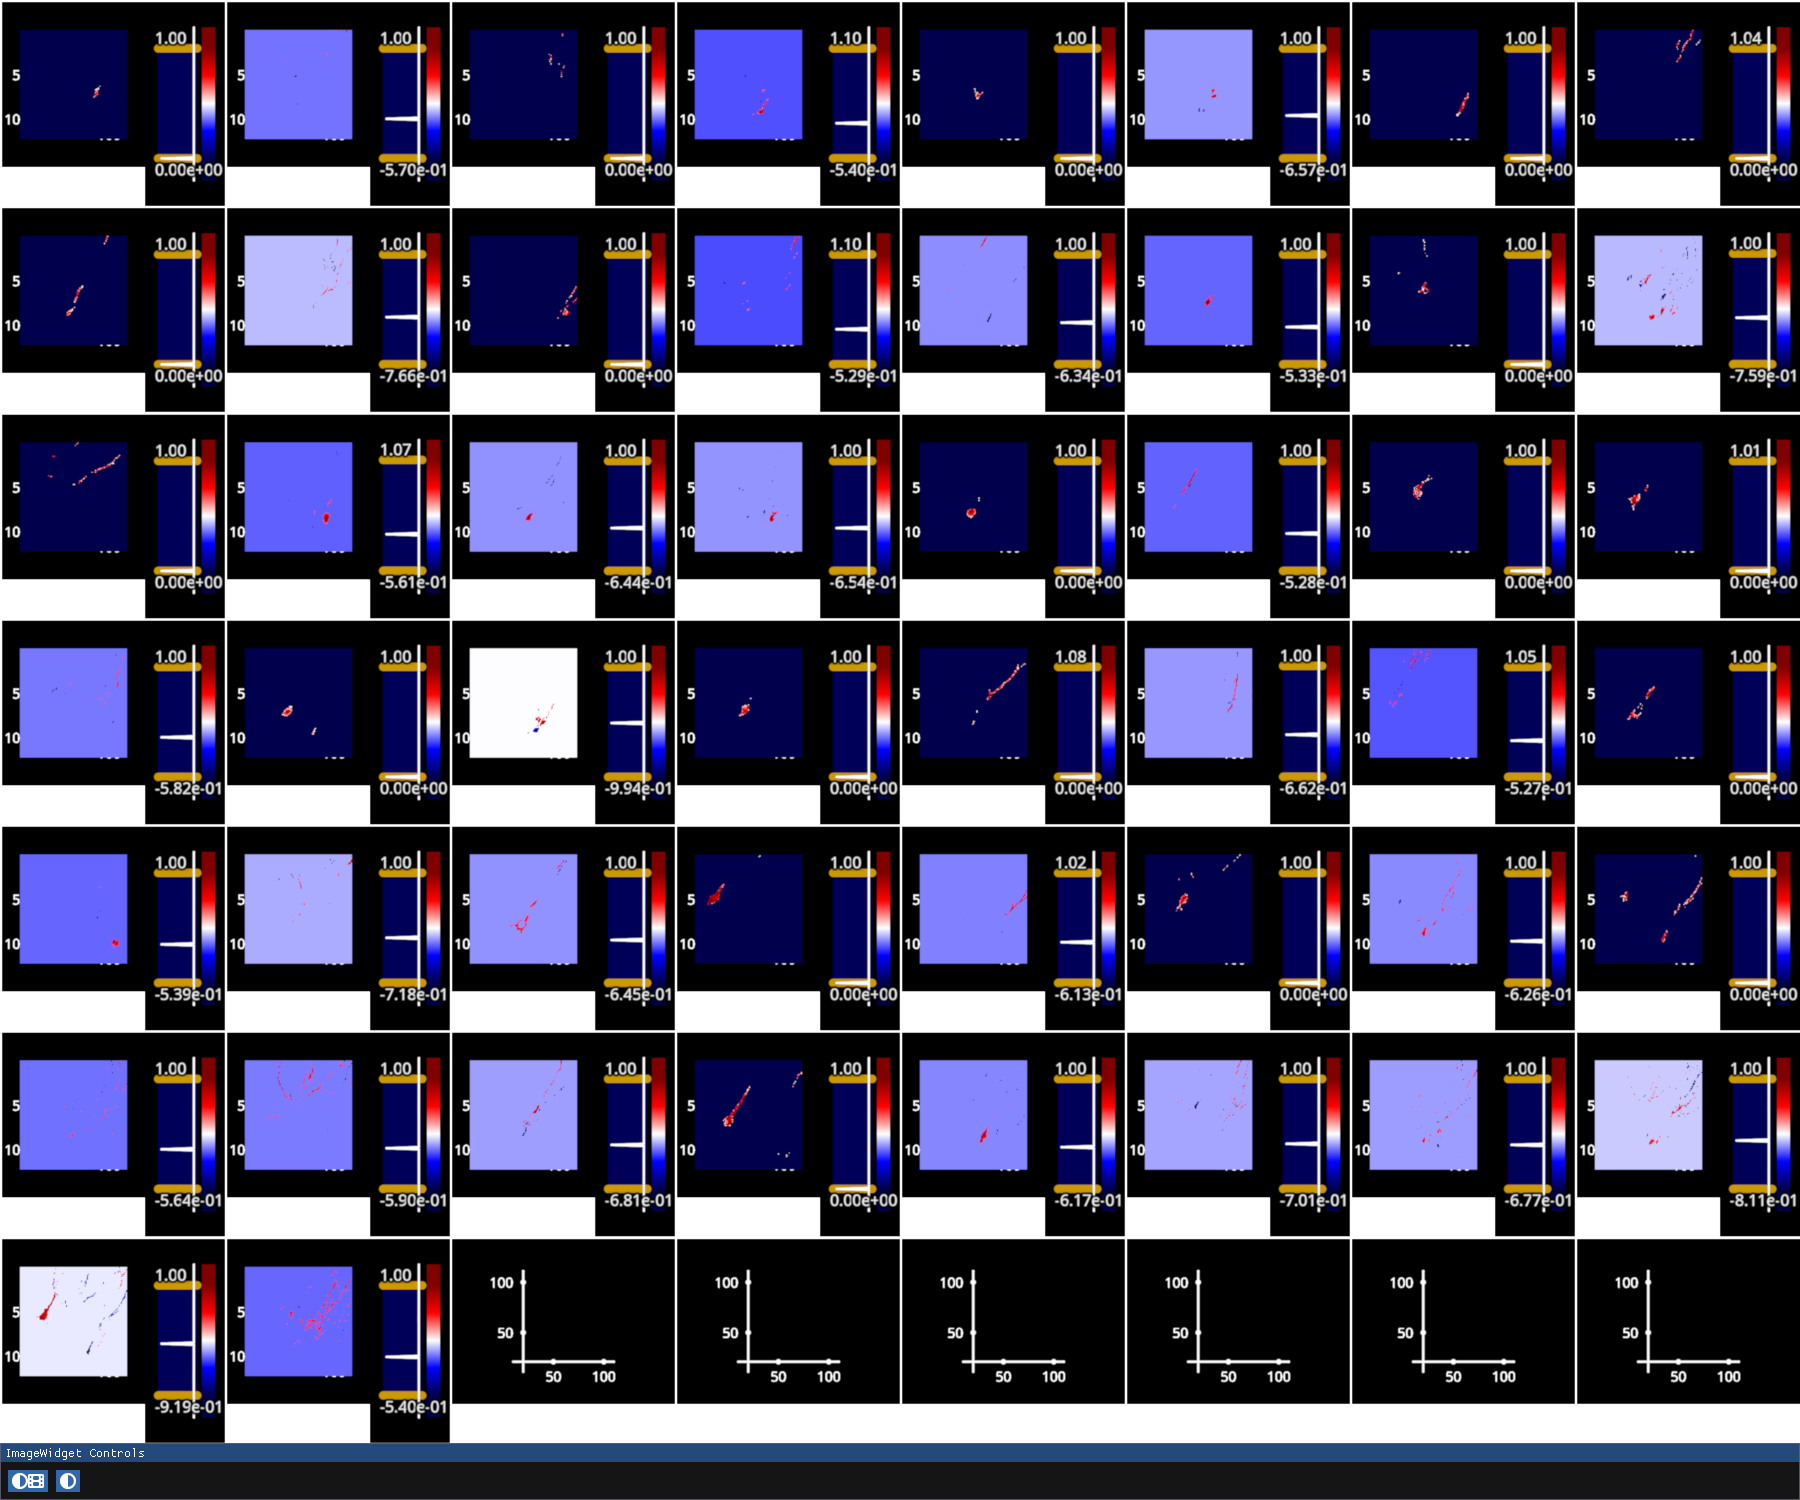

In [44]:
iw_proj_images = fpl.ImageWidget(
    [p for p in proj_images], 
    cmap="seismic",
    figure_kwargs={"size": (1800, 1500)},
)
iw_proj_images.show()

RFBOutputContext()

JupyterWgpuCanvas()
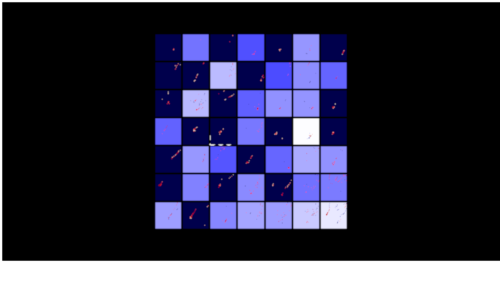

In [45]:
fig = fpl.Figure()

i = 0
for col_ix in range(7):
    for row_ix in range(7):
        img = proj_images[i]
        fig[0, 0].add_image(img, cmap="seismic", offset=(row_ix * (img.shape[1] + 10), col_ix * (img.shape[0] + 10), 0))
        i += 1

fig.show()